In [1]:
from adjoint import *
import numpy as np
import matplotlib.pyplot as plt

font = {"size": 24}

plt.rc("font", **font)

In [2]:
path = "base/delta_f_targ_0.05_f_init_0.045_ell_0_wl_1e-06_f_num_25_conic_-1_nr_1000_r_maxf_5_nzf_501_dz_0.02_steps_5000_lr_5e-11_delta_1_tol_0.01_sg_0_order_0.txt"
params = initialize_variables_from_file(path)
dirname = (path.split("/")[-1])[:-4]
path = "runs/" + dirname

In [3]:
f = 0.5  # focal length of lens
ell = 0  # order of Bessel J function
L=0.01
R=0.05
wl=920e-9
fwhm=27e-15
# print(w0)

k0 = 2 * np.pi / wl  # k=2*pi/wavelength

# zR = np.pi * w0**2 / wl  # Initial rayleigh length
# print(zR)
# print(wl*f**2/(np.pi*R**2))
nr=1000
# Distance parameters
# dz = params["dz"]
# nzf = params["nzf"]
# fl = len(zF) // 2  # focal length index

# Guess parameters
# OoM = math.floor(math.log(w0**2, 10))  # order of magnitude of w0^2
# w_guess = 10**OoM  # guess for the spot size
# steps = params["steps"]  # max number of steps algorithm is allowed
# lr = params["lr"]  # learning rate
# tol = params["tol"]  # tolerance
# delta = params["delta"]  # weighting function in r

In [4]:
def create_axiparabola(r,R,L,f0):
    sag = R**2/(4*L)*np.log(1+L/f0*(r/R)**2)
    return sag

In [5]:
# Hankel
[r, k] = DHTarrays(nr, R, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, R, ell)

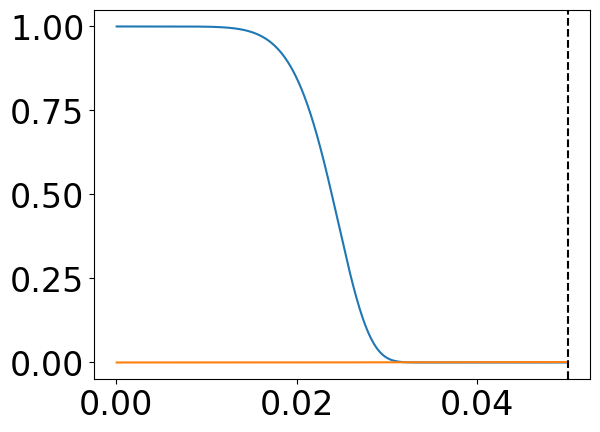

In [6]:
phi_I =  np.exp(-((r / (0.5*R)) ** 8))
plt.plot(r, phi_I)

r_mir = r.copy()
# r_mir[r_mir > R] = 0

zm_t=create_axiparabola(r_mir,R,L,f)
plt.plot(r_mir,zm_t)

plt.axvline(max(r_mir),linestyle="--",color="black")
plt.show()

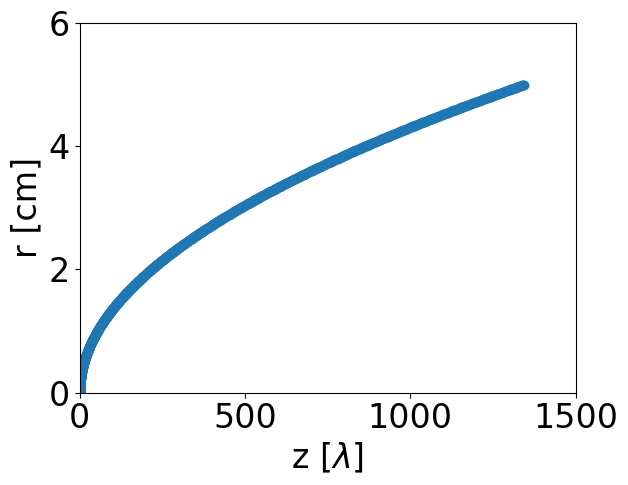

In [7]:
plt.scatter(zm_t/wl,r_mir*100)
plt.xlim([0,1500])
plt.ylim([0,6])
plt.xlabel(r"z [$\lambda$]")
plt.ylabel("r [cm]")
plt.show()

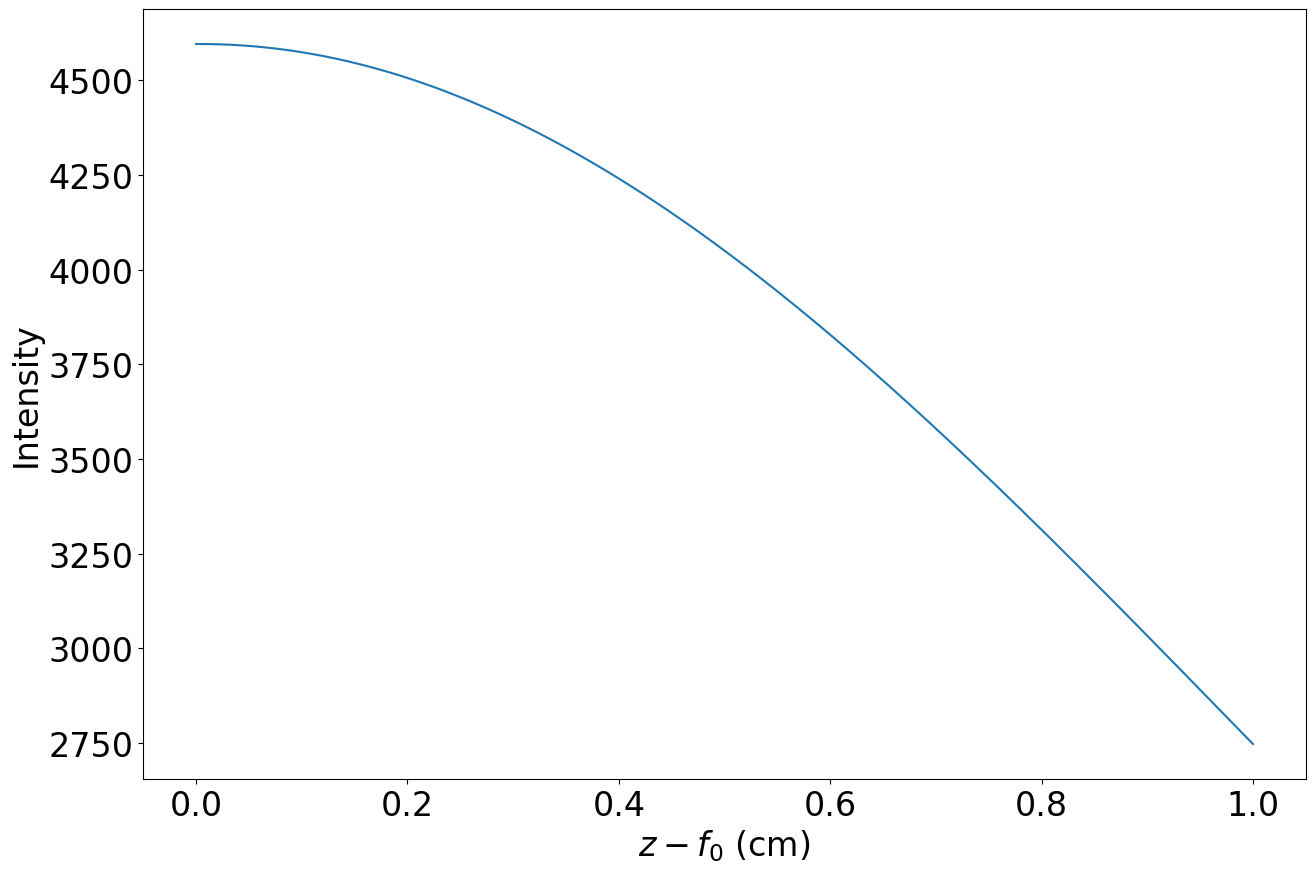

In [8]:
zF = np.linspace(f, f+L, 1000)

ftf_t = forward_propagation(k, phi_I, T_R2K, T_K2R, zF, zm_t)  # Target profile defined using target mirror
plt.figure(figsize=(15,10))
plt.plot((zF-f)*100, np.abs(ftf_t[0,:])**2)
# plt.axvline(x=zm_t[-1], coor="r", linestyle="--", label="Target Mirror")
plt.xlabel(r"$z-f_0$ (cm)")
plt.ylabel("Intensity")
# plt.xlim([0, 0.01])
# plt.legend()
# plt.savefig("axiparabola_adjoint.png")

plt.show()
